

Load the dataset


In [167]:
#mona asghar albloushi
#Part1: Data Quality Detection

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the modified dataset
df = pd.read_csv("brightmart messy dataset.csv")

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display first five rows
display(df.head())

# Check column names and data types
df.info()


Dataset Shape: (64000, 9)


,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion
0,10.0,142.44,1.0,0.0,Surburban,0.0,Phone,Buy One Get One,0
1,6.0,329.08,1.0,1.0,Rural,1.0,Web,No Offer,0
2,7.0,180.65,0.0,1.0,Surburban,1.0,Web,Buy One Get One,0
3,9.0,675.83,1.0,0.0,Rural,1.0,Web,Discount,0
4,2.0,45.34,1.0,0.0,Urban,0.0,Web,Buy One Get One,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   recency        63984 non-null  object 
 1   history        63976 non-null  object 
 2   used_discount  63988 non-null  object 
 3   used_bogo      63988 non-null  float64
 4   zip_code       63982 non-null  object 
 5   is_referral    63988 non-null  float64
 6   channel        63982 non-null  object 
 7   offer          64000 non-null  object 
 8   conversion     64000 non-null  int64  
dtypes: float64(2), int64(1), object(6)
memory usage: 4.4+ MB


Check Missing Values

In [168]:
#mona asghar albloushi

# Check missing values in each column
missing_count = df.isnull().sum()

# Calculate missing value percentages
missing_percentage = (missing_count / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
})

display(missing_summary)

# Total missing values
print("Total Missing Values:", missing_count.sum())


,Missing Values
recency,16
history,24
used_discount,12
used_bogo,12
zip_code,18
is_referral,12
channel,18
offer,0
conversion,0


Total Missing Values: 112


Check Data Types

In [169]:
#mona asghar albloushi

# Check data types of all columns
print("Data Types:")
print(df.dtypes)


Data Types:
recency           object
history           object
used_discount     object
used_bogo        float64
zip_code          object
is_referral      float64
channel           object
offer             object
conversion         int64
dtype: object


Detect Inconsistent Numeric Values

In [170]:
#mona asghar albloushi
# Numeric columns to validate
numeric_columns = [
    "recency",
    "history",
    "used_discount",
    "used_bogo",
    "is_referral"
]

for col in numeric_columns:
    converted = pd.to_numeric(df[col], errors="coerce")

    # Detect non-missing values that fail conversion
    invalid_format = df[col].notna() & converted.isna()

    print(f"\nColumn: {col}")
    print("Inconsistent formats:", invalid_format.sum())
    print("Examples:", df.loc[invalid_format, col].unique()[:10])



Column: recency
Inconsistent formats: 10
Examples: ['9 days' '10 days' '2 days' '6 days']

Column: history
Inconsistent formats: 8
Examples: ['$131.32' '$357.15' '$332.03' '$141.68' '$296.19' '$65.26' '$718.66'
 '$521.24']

Column: used_discount
Inconsistent formats: 8
Examples: ['Yes' 'No']

Column: used_bogo
Inconsistent formats: 0
Examples: []

Column: is_referral
Inconsistent formats: 0
Examples: []


Invalid Value Detection

In [171]:
#mona asghar albloushi
#REMOVE THE NEGATIVE VALUES
# Convert values temporarily for validation
recency_num = pd.to_numeric(df["recency"], errors="coerce")
history_num = pd.to_numeric(df["history"], errors="coerce")

# Detect invalid numeric values
invalid_recency = recency_num.notna() & ~recency_num.between(1, 12)
invalid_history = history_num.notna() & (history_num < 0)

print("Invalid recency values:", invalid_recency.sum())
print("Invalid history values:", invalid_history.sum())

# Display invalid records
display(df.loc[invalid_recency, ["recency"]])
display(df.loc[invalid_history, ["history"]])


Invalid recency values: 3
Invalid history values: 3


,recency
19973,-5
30999,-5
46247,-5


,history
24685,-120.50
27061,-120.50
63638,-120.50


Detect Invalid Binary Values

In [172]:
#mona asghar albloushi
# Check binary variables
binary_columns = [
    "used_discount",
    "used_bogo",
    "is_referral"
]

for col in binary_columns:
    numeric_values = pd.to_numeric(df[col], errors="coerce")

    # Exclude missing values and text-format issues
    invalid_binary = (
        numeric_values.notna()
        & ~numeric_values.isin([0, 1])
    )

    print(f"{col}: {invalid_binary.sum()} invalid values")
    print("Invalid entries:",
          df.loc[invalid_binary, col].unique())


used_discount: 0 invalid values
Invalid entries: []
used_bogo: 3 invalid values
Invalid entries: [3.]
is_referral: 3 invalid values
Invalid entries: [2.]


Detect Invalid Categorical Values

In [173]:
#mona asghar albloushi
# Valid channel categories
valid_channels = ["Web", "Phone", "Multichannel"]

# Detect unsupported categories
invalid_channel = (
    df["channel"].notna()
    & ~df["channel"].isin(valid_channels)
)

print("Invalid channel values:", invalid_channel.sum())

print("Invalid categories:")
print(df.loc[invalid_channel, "channel"].value_counts())


Invalid channel values: 3
Invalid categories:
channel
Satellite    3
Name: count, dtype: int64


Invalid Values Summary

In [174]:
#mona asghar albloushi

invalid_summary = pd.DataFrame({
    "Column": [
        "recency",
        "history",
        "used_bogo",
        "is_referral",
        "channel"
    ],
    "Invalid Values": [
        invalid_recency.sum(),
        invalid_history.sum(),
        (
            pd.to_numeric(df["used_bogo"], errors="coerce")
            .notna()
            & ~pd.to_numeric(
                df["used_bogo"], errors="coerce"
            ).isin([0, 1])
        ).sum(),
        (
            pd.to_numeric(df["is_referral"], errors="coerce")
            .notna()
            & ~pd.to_numeric(
                df["is_referral"], errors="coerce"
            ).isin([0, 1])
        ).sum(),
        invalid_channel.sum()
    ]
})

display(invalid_summary)

print("Total Invalid Values:",
      invalid_summary["Invalid Values"].sum())
#3 negative recency
#3 negative history
# 6 invalid binary values
# 3 unsupported categories

,Column,Invalid Values
0,recency,3
1,history,3
2,used_bogo,3
3,is_referral,3
4,channel,3


Total Invalid Values: 15


Detect outliers using the IQR method

In [175]:
#mona asghar albloushi
# Convert history temporarily to numeric
# Remove currency symbols for detection only
history_numeric = pd.to_numeric(
    df["history"].astype("string").str.replace(
        "$", "", regex=False
    ),
    errors="coerce"
)

# Exclude negative spending (already identified as invalid)
valid_history = history_numeric[
    history_numeric.notna() & (history_numeric >= 0)
]

# Calculate IQR
Q1 = valid_history.quantile(0.25)
Q3 = valid_history.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Detect outliers among valid numeric values
outliers = (
    (history_numeric >= 0)
    & (
        (history_numeric < lower_bound)
        | (history_numeric > upper_bound)
    )
)

print("Q1:", round(Q1, 2))
print("Q3:", round(Q3, 2))
print("IQR:", round(IQR, 2))
print("Lower Bound:", round(lower_bound, 2))
print("Upper Bound:", round(upper_bound, 2))

print("Total Outliers Detected:", outliers.sum())

# Display the 15 highest values
display(
    df.loc[outliers, ["history"]]
    .assign(history_numeric=history_numeric[outliers])
    .sort_values("history_numeric", ascending=False)
    .head(15)
)
#Interquartile Range (IQR) identifies unusually high or low values.
#it shows original spending distribution was already right-skewed.

Q1: 64.69
Q3: 325.79
IQR: 261.1
Lower Bound: -326.96
Upper Bound: 717.44
Total Outliers Detected: 3599


,history,history_numeric
48707,25000.00,25000.0
24683,21000.00,21000.0
35493,18500.00,18500.0
27060,16200.00,16200.0
45815,14500.00,14500.0
50915,12300.00,12300.0
63635,11750.00,11750.0
46239,10500.00,10500.0
19966,9200.00,9200.0
30993,8500.00,8500.0


Visualize outliers using a boxplot

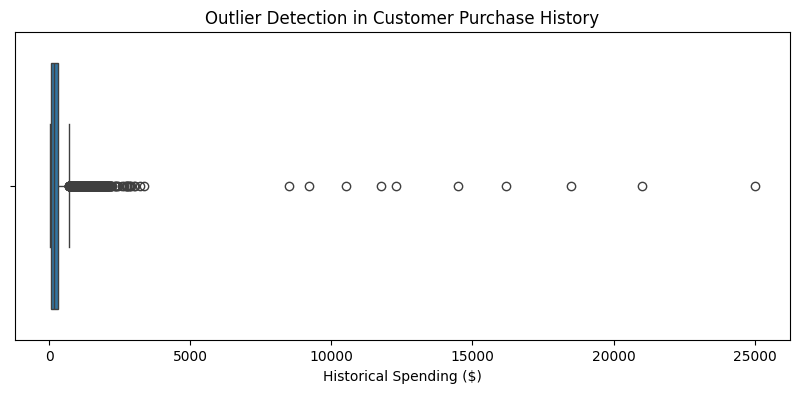

In [176]:
#mona asghar albloushi

plt.figure(figsize=(10, 4))

sns.boxplot(x=valid_history)

plt.title("Outlier Detection in Customer Purchase History")
plt.xlabel("Historical Spending ($)")
plt.show()

#highest introduced value is $25,000
#most of the original values may appear compressed toward the left side.

Examine the distribution

In [177]:
#mona asghar albloushi
print("History Descriptive Statistics:")
display(valid_history.describe())


#This helps us distinguish potentially legitimate
#high-spending customers from unusually extreme values.



History Descriptive Statistics:


,history
count,63973.0
mean,244.376701
std,320.333052
min,29.99
25%,64.69
50%,158.14
75%,325.79
max,25000.0


Duplicate Record Detection

In [178]:
#mona asghar albloushi
#Count duplicate records

# Detect exact duplicate rows
duplicate_mask = df.duplicated()

# Count duplicates
duplicate_count = duplicate_mask.sum()

# Calculate percentage
duplicate_percentage = (
    duplicate_count / len(df)
) * 100

print("Total Records:", len(df))
print("Duplicate Records:", duplicate_count)
print(
    "Duplicate Percentage:",
    round(duplicate_percentage, 2), "%"
)


#Display duplicate examples
# Display examples of duplicated rows
display(df[df.duplicated(keep=False)].head(10))


Total Records: 64000
Duplicate Records: 6583
Duplicate Percentage: 10.29 %


,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion
16,5.0,29.99,1.0,0.0,Surburban,0.0,Phone,Discount,0
20,9.0,29.99,0.0,1.0,Surburban,1.0,Phone,No Offer,0
23,2.0,29.99,0.0,1.0,Urban,1.0,Phone,No Offer,0
33,9.0,29.99,1.0,0.0,Surburban,1.0,Phone,Discount,0
34,3.0,29.99,1.0,0.0,Rural,0.0,Web,Buy One Get One,0
45,10.0,29.99,1.0,0.0,Surburban,0.0,Phone,No Offer,0
52,7.0,29.99,0.0,1.0,Urban,1.0,Phone,Discount,0
79,2.0,29.99,0.0,1.0,Surburban,0.0,Phone,Discount,0
107,12.0,29.99,0.0,1.0,Urban,1.0,Web,No Offer,0
114,4.0,29.99,0.0,1.0,Urban,1.0,Web,Buy One Get One,0


Display all categorical values

In [179]:
#mona asghar albloushi

categorical_columns = [
    "zip_code",
    "channel",
    "offer"
]

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print("Unique Values:")
    print(df[col].unique())

    print("\nValue Counts:")
    print(df[col].value_counts(dropna=False))

#We need to check for
#spelling errors, inconsistent labels, unexpected categories, and missing values.


Column: zip_code
Unique Values:
['Surburban' 'Rural' 'Urban' nan]

Value Counts:
zip_code
Surburban    28767
Urban        25652
Rural         9563
NaN             18
Name: count, dtype: int64

Column: channel
Unique Values:
['Phone' 'Web' 'Multichannel' nan 'Satellite']

Value Counts:
channel
Web             28209
Phone           28009
Multichannel     7761
NaN                18
Satellite           3
Name: count, dtype: int64

Column: offer
Unique Values:
['Buy One Get One' 'No Offer' 'Discount']

Value Counts:
offer
Buy One Get One    21387
Discount           21307
No Offer           21306
Name: count, dtype: int64


Validate categorical values

In [180]:
#Mona Asghar Albloushi
# Define expected categories
valid_categories = {
    "zip_code": ["Urban", "Rural", "Suburban"],
    "channel": ["Web", "Phone", "Multichannel"],
    "offer": ["Discount", "Buy One Get One", "No Offer"]
}

# Check unexpected categories
for col, allowed_values in valid_categories.items():

    unexpected = (
        df[col].notna()
        & ~df[col].isin(allowed_values)
    )

    print(f"\nColumn: {col}")
    print("Unexpected Values:", unexpected.sum())

    print("Unexpected Categories:")
    print(df.loc[unexpected, col].value_counts())

#Surburban typo existed in the original dataset
#It is not one of the 15 newly introduced invalid values.
#Surburban instead of Suburban==>zip code
#3 records containing Satellite==>channel
#	No introduced category issues==>offer


Column: zip_code
Unexpected Values: 28767
Unexpected Categories:
zip_code
Surburban    28767
Name: count, dtype: int64

Column: channel
Unexpected Values: 3
Unexpected Categories:
channel
Satellite    3
Name: count, dtype: int64

Column: offer
Unexpected Values: 0
Unexpected Categories:
Series([], Name: count, dtype: int64)


Data Quality Detection

In [181]:
#Mona Asghar Albloushi

# Final verification of Data Quality Detection
print("Dataset Shape:", df.shape)
print("Missing Values:", df.isna().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nChannel Categories:")
print(df["channel"].value_counts(dropna=False))

print("\nZip Code Categories:")
print(df["zip_code"].value_counts(dropna=False))


Dataset Shape: (64000, 9)
Missing Values: 112
Duplicate Rows: 6583

Channel Categories:
channel
Web             28209
Phone           28009
Multichannel     7761
NaN                18
Satellite           3
Name: count, dtype: int64

Zip Code Categories:
zip_code
Surburban    28767
Urban        25652
Rural         9563
NaN             18
Name: count, dtype: int64


Part 2 — Data Cleaning

In [182]:
#Shaikah Ali Omran
#Part 2 Data Cleaning


# Convert recency to numeric

df["recency"] = pd.to_numeric(
    df["recency"].astype("string")
    .str.replace(r"\s*days\s*$", "", regex=True),
    errors="coerce"
)

# Remove dollar signs from history
df["history"] = df["history"].str.replace(
    "$", "", regex=False
)

# Convert history to numeric
df["history"] = pd.to_numeric(
    df["history"], errors="coerce"
)

# Convert Yes/No into 1/0
df["used_discount"] = df["used_discount"].replace({
    "Yes": 1,
    "No": 0
})

df["used_discount"] = pd.to_numeric(
    df["used_discount"], errors="coerce"
)

# Fix spelling mistake
df["zip_code"] = df["zip_code"].replace(
    "Surburban", "Suburban"
)

print(df.dtypes)

recency          Float64
history          float64
used_discount    float64
used_bogo        float64
zip_code          object
is_referral      float64
channel           object
offer             object
conversion         int64
dtype: object


In [183]:
#Shaikah Ali Omran

# Fix invalid values
# Explanation: We change invalid values into missing values because we don't know their correct original values. We can then handle them using an appropriate method.

# Invalid recency values
df.loc[~df["recency"].between(1, 12), "recency"] = np.nan

# Negative historical spending
df.loc[df["history"] < 0, "history"] = np.nan

# Invalid binary values
df.loc[~df["used_bogo"].isin([0, 1]), "used_bogo"] = np.nan
df.loc[~df["is_referral"].isin([0, 1]), "is_referral"] = np.nan

# Invalid channel categories
valid_channels = ["Web", "Phone", "Multichannel"]

df.loc[~df["channel"].isin(valid_channels), "channel"] = np.nan

print(df.isnull().sum())


recency          19
history          27
used_discount    12
used_bogo        15
zip_code         18
is_referral      15
channel          21
offer             0
conversion        0
dtype: int64


In [184]:
#Shaikah Ali Omran

#Handle missing values
#Median: Middle value, useful for numerical data because it is less affected by outliers.
#Mode: Most frequent value, useful for categorical and binary columns.




# Fill numeric columns using the median
df["recency"] = df["recency"].fillna(df["recency"].median())
df["history"] = df["history"].fillna(df["history"].median())

# Fill categorical/binary columns using the mode
columns = [
    "used_discount",
    "used_bogo",
    "is_referral",
    "zip_code",
    "channel"
]

for col in columns:
    df[col] = df[col].fillna(df[col].mode()[0])

# Convert integer columns to integers
for col in ["recency", "used_discount", "used_bogo", "is_referral"]:
    df[col] = df[col].astype(int)

print(df.isnull().sum())


recency          0
history          0
used_discount    0
used_bogo        0
zip_code         0
is_referral      0
channel          0
offer            0
conversion       0
dtype: int64


In [185]:
#Shaikah Ali Omran

#Handle duplicate rows
##Explanation: Your dataset has no unique customer ID.
#Two customers could have exactly the same recorded values, so we cannot confidently identify duplicates as errors.


# Check duplicates after cleaning
duplicates = df.duplicated().sum()

print("Duplicate rows:", duplicates)
print("Total rows:", len(df))


Duplicate rows: 6598
Total rows: 64000


In [186]:
#Shaikah Ali Omran
# Count duplicate rows
print("Number of duplicates:", df.duplicated().sum())

# Display duplicate rows
display(df[df.duplicated()].head(10))

#keeping the duplicates since they could be different customers with the same inforamtion


Number of duplicates: 6598


,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion
149,2,29.99,0,1,Suburban,0,Phone,Discount,0
167,7,29.99,1,0,Suburban,1,Web,Buy One Get One,0
526,10,29.99,1,0,Urban,0,Web,Buy One Get One,0
654,10,29.99,1,0,Urban,0,Web,Buy One Get One,0
792,9,29.99,0,1,Suburban,0,Phone,No Offer,0
807,9,29.99,0,1,Suburban,1,Phone,No Offer,0
883,9,29.99,0,1,Suburban,0,Phone,Buy One Get One,0
924,10,29.99,1,0,Urban,0,Web,Buy One Get One,0
937,6,29.99,0,1,Urban,1,Web,Discount,0
949,9,29.99,0,1,Suburban,0,Phone,Buy One Get One,0


In [187]:
#Shaikah Ali Omran
#Handle outliers

# Count extreme values
print("Extreme values:", (df["history"] > 3345.93).sum())

# Cap extreme spending at the original dataset maximum
df["history"] = df["history"].clip(upper=3345.93)

print("Maximum spending:", df["history"].max())


Extreme values: 10
Maximum spending: 3345.93


In [188]:
#Shaikah Ali Omran
#after data cleaning

# Check the cleaned dataset
print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nData types:")
print(df.dtypes)

print("\nRecency range:")
print(df["recency"].min(), df["recency"].max())

print("\nHistory range:")
print(df["history"].min(), df["history"].max())


Dataset shape: (64000, 9)
Missing values: 0
Duplicate rows: 6598

Data types:
recency            int64
history          float64
used_discount      int64
used_bogo          int64
zip_code          object
is_referral        int64
channel           object
offer             object
conversion         int64
dtype: object

Recency range:
1 12

History range:
29.99 3345.93


Upload Cleaned data

In [189]:
#Shaikah Ali Omran
#Conversion rate by offer

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the modified dataset
df = pd.read_csv("Orignal-data.csv")

# Check dataset dimensions
print("Dataset Shape:", df.shape)

# Display first five rows
display(df.head())

# Check column names and data types
df.info()




Dataset Shape: (64000, 9)


,recency,history,used_discount,used_bogo,zip_code,is_referral,channel,offer,conversion
0,10,142.44,1,0,Surburban,0,Phone,Buy One Get One,0
1,6,329.08,1,1,Rural,1,Web,No Offer,0
2,7,180.65,0,1,Surburban,1,Web,Buy One Get One,0
3,9,675.83,1,0,Rural,1,Web,Discount,0
4,2,45.34,1,0,Urban,0,Web,Buy One Get One,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64000 entries, 0 to 63999
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   recency        64000 non-null  int64  
 1   history        64000 non-null  float64
 2   used_discount  64000 non-null  int64  
 3   used_bogo      64000 non-null  int64  
 4   zip_code       64000 non-null  object 
 5   is_referral    64000 non-null  int64  
 6   channel        64000 non-null  object 
 7   offer          64000 non-null  object 
 8   conversion     64000 non-null  int64  
dtypes: float64(1), int64(5), object(3)
memory usage: 4.4+ MB



Part 3 Exploratory Data Analysis (EDA)



A- Dataset and Campaign Overview

In [190]:
#Shaikah Ali Omran
#Descriptive Statistics
# Generate descriptive statistics for numerical variables
print("Numerical Descriptive Statistics:")
display(df.describe().round(2))

# Generate descriptive statistics for categorical variables
print("\nCategorical Descriptive Statistics:")
display(df.describe(include=["object"]))


Numerical Descriptive Statistics:


,recency,history,used_discount,used_bogo,is_referral,conversion
count,64000.00,64000.00,64000.00,64000.00,64000.0,64000.00
mean,5.76,242.09,0.55,0.55,0.5,0.15
std,3.51,256.16,0.50,0.50,0.5,0.35
min,1.00,29.99,0.00,0.00,0.0,0.00
25%,2.00,64.66,0.00,0.00,0.0,0.00
50%,6.00,158.11,1.00,1.00,1.0,0.00
75%,9.00,325.66,1.00,1.00,1.0,0.00
max,12.00,3345.93,1.00,1.00,1.0,1.00



Categorical Descriptive Statistics:


,zip_code,channel,offer
count,64000,64000,64000
unique,3,3,3
top,Surburban,Web,Buy One Get One
freq,28776,28217,21387


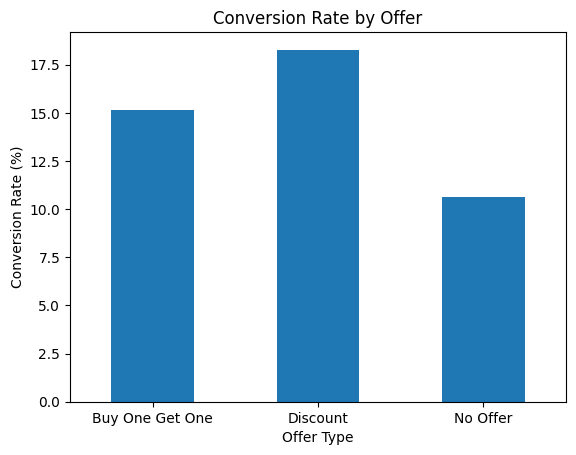

In [191]:
#Shaikah Ali Omran

# Calculate conversion percentage
conversion_rate = df.groupby("offer")["conversion"].mean() * 100

# Plot
conversion_rate.plot(kind="bar")

plt.title("Conversion Rate by Offer")
plt.xlabel("Offer Type")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.show()

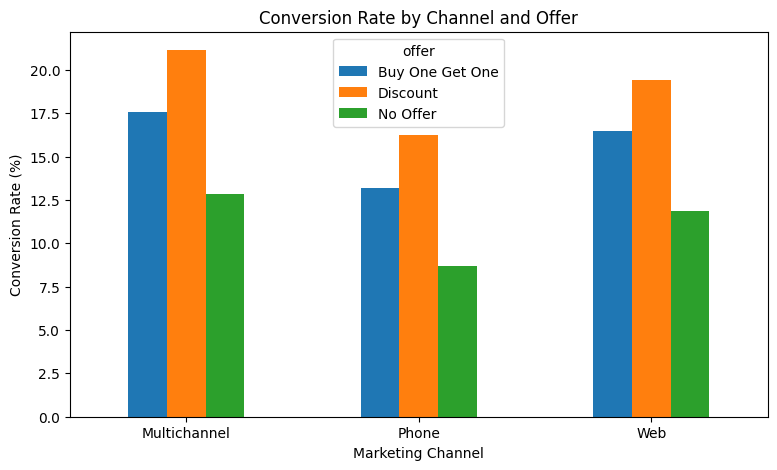

In [192]:
#Shaikah Ali Omran
#Conversion rate by channel and offer

# Compare conversion rates
channel_rate = df.groupby(
    ["channel", "offer"]
)["conversion"].mean().unstack() * 100

channel_rate.plot(kind="bar", figsize=(9, 5))

plt.title("Conversion Rate by Channel and Offer")
plt.xlabel("Marketing Channel")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.show()



B — Customer Behavior Analysis

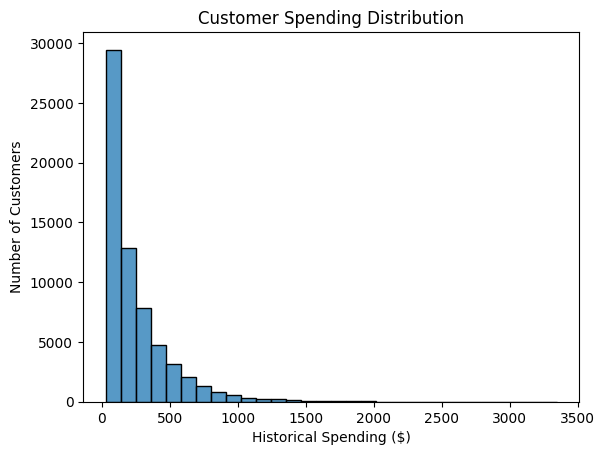

In [193]:
#Historical spending distribution

# Display spending distribution
sns.histplot(df["history"], bins=30)

plt.title("Customer Spending Distribution")
plt.xlabel("Historical Spending ($)")
plt.ylabel("Number of Customers")
plt.show()


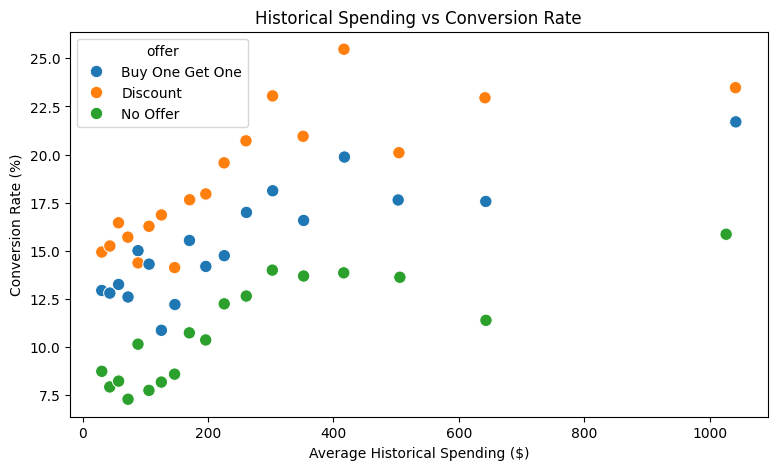

In [194]:
#Shaikah Ali Omran

#Historical Spending vs. Conversion Rate clustering
# Divide customers into 20 spending groups
spending_groups = pd.qcut(df["history"], 20, duplicates="drop")

# Calculate average spending and conversion rate
plot_data = df.groupby(
    [spending_groups, "offer"], observed=True
).agg(
    avg_spending=("history", "mean"),
    conversion_rate=("conversion", "mean")
).reset_index()

# Convert conversion rate to percentage
plot_data["conversion_rate"] *= 100

# Create scatter plot
plt.figure(figsize=(9, 5))

sns.scatterplot(
    data=plot_data,
    x="avg_spending",
    y="conversion_rate",
    hue="offer",
    s=80
)

plt.title("Historical Spending vs Conversion Rate")
plt.xlabel("Average Historical Spending ($)")
plt.ylabel("Conversion Rate (%)")
plt.show()


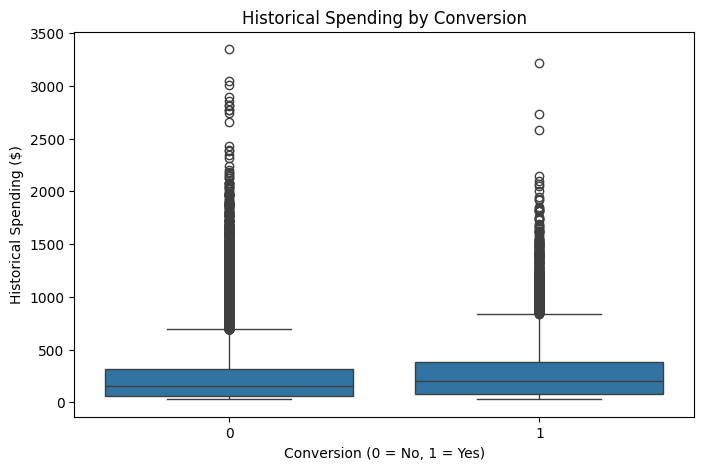

In [195]:
#Shaikah Ali Omran

# Boxplot: Historical Spending by Conversion
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="conversion", y="history")

plt.title("Historical Spending by Conversion")
plt.xlabel("Conversion (0 = No, 1 = Yes)")
plt.ylabel("Historical Spending ($)")
plt.show()


offer,Buy One Get One,Discount,No Offer
recency,,,
1,19.75,23.32,14.84
2,17.74,22.14,13.43
3,16.36,20.89,12.60
4,14.12,19.47,11.16
5,14.95,16.83,11.01
6,14.84,17.89,9.49
7,14.65,15.71,10.01
8,13.90,15.43,9.02
9,12.70,14.84,6.54


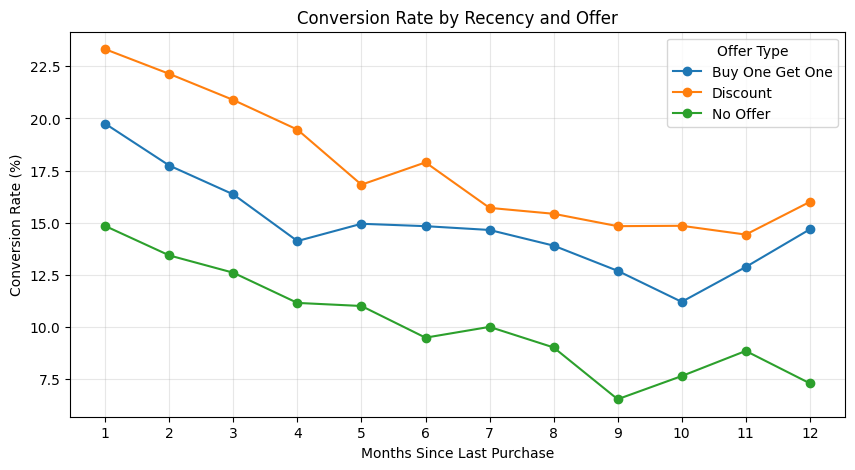

In [196]:
#mona asghar walid
# Conversion Rate by Recency and Offer

# Calculate conversion rates for each recency value
recency_rate = (
    df.groupby(["recency", "offer"])["conversion"]
    .mean()
    .unstack() * 100
)

# Display results
display(recency_rate.round(2))

# Plot conversion rates
recency_rate.plot(
    kind="line",
    marker="o",
    figsize=(10, 5)
)

plt.title("Conversion Rate by Recency and Offer")
plt.xlabel("Months Since Last Purchase")
plt.ylabel("Conversion Rate (%)")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.legend(title="Offer Type")
plt.show()

#The No Offer conversion rate generally decreases as months since the last purchase increase. This helps investigate baseline purchase probability
#whether recency may be useful for predicting promotional effects.
#Who benefits from a discount, and who might purchase without one?
#whether customers who previously used discounts show different promotional responses compared with customers who never used discounts.

Conversion Rate by Previous Discount Usage and Offer:


offer,Buy One Get One,Discount,No Offer
used_discount,,,
0,16.98,16.64,9.58
1,13.63,19.61,11.45


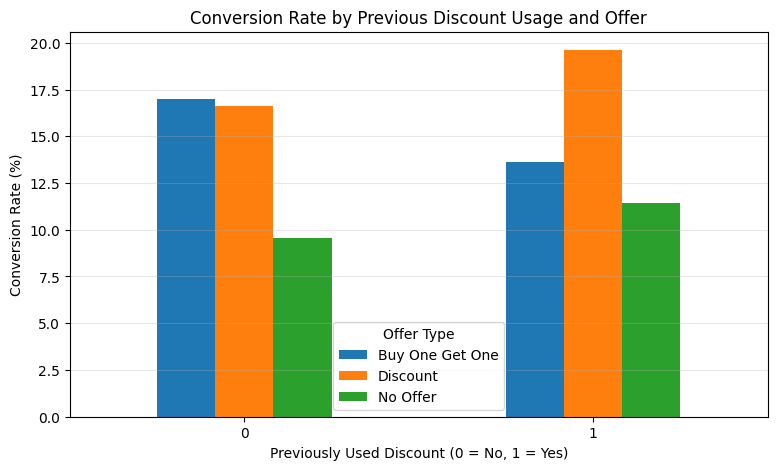

In [197]:
#Mona Asghar walid
# Conversion Rate by Previous Discount Usage and Offer

# Calculate conversion rates
discount_usage_rate = (
    df.groupby(["used_discount", "offer"])["conversion"]
    .mean()
    .unstack() * 100
)

# Display results
print("Conversion Rate by Previous Discount Usage and Offer:")
display(discount_usage_rate.round(2))

# Create grouped bar chart
discount_usage_rate.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Conversion Rate by Previous Discount Usage and Offer")
plt.xlabel("Previously Used Discount (0 = No, 1 = Yes)")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Offer Type")
plt.grid(axis="y", alpha=0.3)
plt.show()

#Previous discount users have an observed Discount lift of +8.16 pp, compared with +7.06 pp for non-users. Past discount behavior is a reasonable candidate predictor.
#Do customers who previously used discounts respond differently to new promotional offers compared with customers who have never used discounts?
#BOGO showed a larger observed lift among customers without prior discount usage (7.40 percentage points) than among previous discount users (2.18 percentage points).

Conversion Rate by Previous BOGO Usage and Offer:


offer,Buy One Get One,Discount,No Offer
used_bogo,,,
0,11.09,16.9,9.98
1,18.45,19.4,11.14


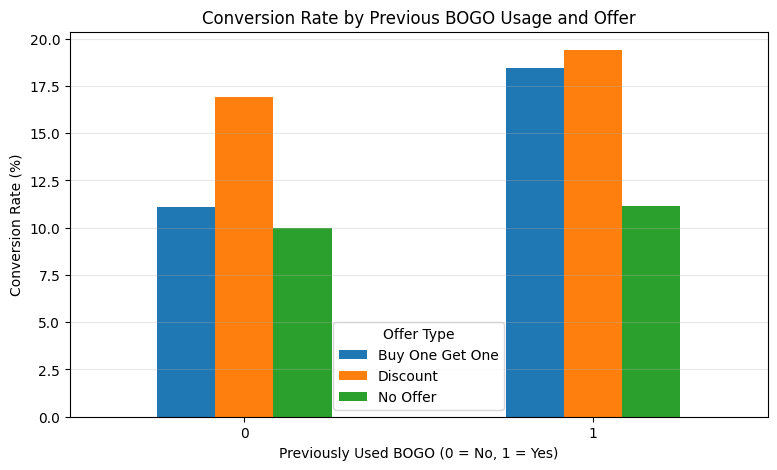

In [198]:
#mona asghar walid
# Conversion Rate by Previous BOGO Usage and Offer

# Calculate conversion rates
bogo_usage_rate = (
    df.groupby(["used_bogo", "offer"])["conversion"]
    .mean()
    .unstack() * 100
)

# Display results
print("Conversion Rate by Previous BOGO Usage and Offer:")
display(bogo_usage_rate.round(2))

# Create grouped bar chart
bogo_usage_rate.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Conversion Rate by Previous BOGO Usage and Offer")
plt.xlabel("Previously Used BOGO (0 = No, 1 = Yes)")
plt.ylabel("Conversion Rate (%)")
plt.xticks(rotation=0)
plt.legend(title="Offer Type")
plt.grid(axis="y", alpha=0.3)
plt.show()

#BOGO lift is +7.31 pp for previous BOGO users versus +1.11 pp for non-users
# suggesting possible differences in treatment response.
#This is your most directly relevant analysis. It compares Discount and BOGO against No Offer across customer segments
#rather than focusing only on conversion rates.

C — Promotional Effect Analysis

In [199]:
#mona asghar walid
# Treatment-Control Conversion Difference by Customer Segment

# Select customer features
segment_features = [
    "used_discount",
    "used_bogo",
    "channel"
]

results = []

for feature in segment_features:

    # Calculate conversion rates and sample sizes
    summary = (
        df.groupby([feature, "offer"])["conversion"]
        .agg(["mean", "size"])
        .reset_index()
    )

    rates = summary.pivot(
        index=feature,
        columns="offer",
        values="mean"
    ) * 100

    counts = summary.pivot(
        index=feature,
        columns="offer",
        values="size"
    )

    # Calculate treatment-control differences
    lift = pd.DataFrame({
        "Discount":
            rates["Discount"] - rates["No Offer"],

        "BOGO":
            rates["Buy One Get One"] - rates["No Offer"]
    })

    # Keep group sizes for interpretation
    lift["Discount "] = counts["Discount"]
    lift["BOGO "] = counts["Buy One Get One"]
    lift["Control "] = counts["No Offer"]

    lift["Feature"] = feature
    lift["Segment"] = lift.index.astype(str)

    results.append(lift.reset_index(drop=True))

# Combine all segment results
lift_results = pd.concat(results, ignore_index=True)

# Display summary
print("Observed Promotional Lift by Customer Segment:")
display(lift_results.round(2))

#It compares Discount and BOGO against No Offer across customer segments, rather than focusing only on conversion rates.
#compared conversion-rate differences between promotional treatment groups (Discount and BOGO) and the untreated control group (No Offer) across customer segments.

Observed Promotional Lift by Customer Segment:


,Discount,BOGO,Discount,BOGO,Control,Feature,Segment
0,7.06,7.40,9568,9647,9519,used_discount,0
1,8.16,2.18,11739,11740,11787,used_discount,1
2,6.92,1.11,9558,9622,9638,used_bogo,0
3,8.26,7.31,11749,11765,11668,used_bogo,1
4,8.29,4.71,2577,2579,2606,channel,Multichannel
5,7.56,4.46,9240,9454,9327,channel,Phone
6,7.56,4.57,9490,9354,9373,channel,Web


In [200]:
#mona asghar walid
import pandas as pd
import numpy as np
from scipy.stats import norm

# 95% Confidence Intervals for Promotional Lift
# Compare each promotion against the No Offer control group

features = ["used_discount", "used_bogo", "channel"]
z = norm.ppf(0.975)
results = []

for feature in features:
    for segment, group in df.groupby(feature):

        control = group[group["offer"] == "No Offer"]
        n0 = len(control)

        if n0 == 0:
            continue

        p0 = control["conversion"].mean()

        for treatment in ["Discount", "Buy One Get One"]:
            treated = group[group["offer"] == treatment]
            n1 = len(treated)

            if n1 == 0:
                continue

            p1 = treated["conversion"].mean()

            # Observed promotional lift
            lift = p1 - p0

            # Standard error for difference in proportions
            se = np.sqrt(
                p1 * (1 - p1) / n1 +
                p0 * (1 - p0) / n0
            )

            # 95% confidence interval
            lower = lift - z * se
            upper = lift + z * se

            results.append({
                "Feature": feature,
                "Segment": segment,
                "Treatment": treatment,
                "Treatment N": n1,
                "Control N": n0,
                "Lift (pp)": round(lift * 100, 2),
                "95% CI Lower (pp)": round(lower * 100, 2),
                "95% CI Upper (pp)": round(upper * 100, 2),
                "CI Excludes Zero": lower > 0 or upper < 0
            })

ci_results = pd.DataFrame(results)

print("95% Confidence Intervals for Promotional Lift:")
display(ci_results)

#95% confidence intervals for promotional lift across customer segments based on previous discount usage


95% Confidence Intervals for Promotional Lift:


,Feature,Segment,Treatment,Treatment N,Control N,Lift (pp),95% CI Lower (pp),95% CI Upper (pp),CI Excludes Zero
0,used_discount,0,Discount,9568,9519,7.06,6.11,8.01,True
1,used_discount,0,Buy One Get One,9647,9519,7.40,6.44,8.35,True
2,used_discount,1,Discount,11739,11787,8.16,7.24,9.08,True
3,used_discount,1,Buy One Get One,11740,11787,2.18,1.33,3.02,True
4,used_bogo,0,Discount,9558,9638,6.92,5.96,7.88,True
5,used_bogo,0,Buy One Get One,9622,9638,1.11,0.24,1.97,True
6,used_bogo,1,Discount,11749,11668,8.26,7.34,9.17,True
7,used_bogo,1,Buy One Get One,11765,11668,7.31,6.41,8.22,True
8,channel,Multichannel,Discount,2577,2606,8.29,6.26,10.33,True
9,channel,Multichannel,Buy One Get One,2579,2606,4.71,2.76,6.66,True


Part 4 feature engineering

In [201]:
#Shaikah Ali Omran

#create new features

# Identify customers who purchased recently
df["recent_customer"] = (df["recency"] <= 3).astype(int)

# Identify customers who previously used any promotion
df["used_any_promo"] = (
    (df["used_discount"] == 1) |
    (df["used_bogo"] == 1)
).astype(int)

# Reduce spending skewness
df["history_log"] = np.log1p(df["history"])

# Display the new features
df[["recent_customer", "used_any_promo", "history_log"]].head()


,recent_customer,used_any_promo,history_log
0,0,1,4.965917
1,0,1,5.799335
2,0,1,5.202082
3,0,1,6.517420
4,1,1,3.836006


Verify your new features

In [202]:
#mona asghar walid
# Verify engineered features

new_features = [
    "recent_customer",
    "used_any_promo",
    "history_log"
]

print("New Feature Data Types:")
print(df[new_features].dtypes)

print("\nMissing Values:")
print(df[new_features].isnull().sum())

print("\nRecent Customer Distribution:")
print(df["recent_customer"].value_counts())

print("\nPrevious Promotion Usage:")
print(df["used_any_promo"].value_counts())

print("\nHistorical Spending Transformation:")
print(df[["history", "history_log"]].describe())


New Feature Data Types:
recent_customer      int64
used_any_promo       int64
history_log        float64
dtype: object

Missing Values:
recent_customer    0
used_any_promo     0
history_log        0
dtype: int64

Recent Customer Distribution:
recent_customer
0    41607
1    22393
Name: count, dtype: int64

Previous Promotion Usage:
used_any_promo
1    64000
Name: count, dtype: int64

Historical Spending Transformation:
            history   history_log
count  64000.000000  64000.000000
mean     242.085656      5.006653
std      256.158608      1.019251
min       29.990000      3.433665
25%       64.660000      4.184490
50%      158.110000      5.069596
75%      325.657500      5.788912
max     3345.930000      8.115799


Encode Categorical Variables

In [203]:
#mona asghar walid

# Encode Categorical Variables

# Create a copy for encoding
df_encoded = df.copy()

# One-Hot Encode categorical predictors
df_encoded = pd.get_dummies(
    df_encoded,
    columns=["zip_code", "channel"],
    dtype=int
)

# Display encoded dataset
print("Dataset Shape:", df_encoded.shape)

print("\nEncoded Columns:")
print(df_encoded.columns.tolist())

# Display first 5 rows
display(df_encoded.head())


Dataset Shape: (64000, 16)

Encoded Columns:
['recency', 'history', 'used_discount', 'used_bogo', 'is_referral', 'offer', 'conversion', 'recent_customer', 'used_any_promo', 'history_log', 'zip_code_Rural', 'zip_code_Surburban', 'zip_code_Urban', 'channel_Multichannel', 'channel_Phone', 'channel_Web']


,recency,history,used_discount,used_bogo,is_referral,offer,conversion,recent_customer,used_any_promo,history_log,zip_code_Rural,zip_code_Surburban,zip_code_Urban,channel_Multichannel,channel_Phone,channel_Web
0,10,142.44,1,0,0,Buy One Get One,0,0,1,4.965917,0,1,0,0,1,0
1,6,329.08,1,1,1,No Offer,0,0,1,5.799335,1,0,0,0,0,1
2,7,180.65,0,1,1,Buy One Get One,0,0,1,5.202082,0,1,0,0,0,1
3,9,675.83,1,0,1,Discount,0,0,1,6.517420,1,0,0,0,0,1
4,2,45.34,1,0,0,Buy One Get One,0,1,1,3.836006,0,0,1,0,0,1


Prepare Treatment and Control Groups

In [204]:

#mona asghar walid
#Prepare Treatment and Control Groups

# Separate customers by assigned offer
discount_group = df_encoded[
    df_encoded["offer"] == "Discount"
].copy()

bogo_group = df_encoded[
    df_encoded["offer"] == "Buy One Get One"
].copy()

control_group = df_encoded[
    df_encoded["offer"] == "No Offer"
].copy()

# Display group sizes
print("Discount Group:", len(discount_group))
print("BOGO Group:", len(bogo_group))
print("Control Group:", len(control_group))

# Verify total observations
total = (
    len(discount_group)
    + len(bogo_group)
    + len(control_group)
)

print("\nTotal Records:", total)
print("Original Records:", len(df_encoded))

assert total == len(df_encoded)


Discount Group: 21307
BOGO Group: 21387
Control Group: 21306

Total Records: 64000
Original Records: 64000


Data Train/Test Split

In [205]:

#mona asghar walid

#Train/Test Split
from sklearn.model_selection import train_test_split

# Stratify by treatment and conversion
stratify_labels = (
    df["offer"].astype(str)
    + "_"
    + df["conversion"].astype(str)
)

# Split the original dataset before model preprocessing
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=stratify_labels
)

# Display dataset sizes
print("Training Set:", train_df.shape)
print("Testing Set:", test_df.shape)

# Verify treatment distribution
print("\nTraining Treatment Distribution:")
print(train_df["offer"].value_counts())

print("\nTesting Treatment Distribution:")
print(test_df["offer"].value_counts())

# Verify no overlapping records by index
print("\nOverlapping Row Indices:",
      len(set(train_df.index) & set(test_df.index)))


Training Set: (51200, 12)
Testing Set: (12800, 12)

Training Treatment Distribution:
offer
Buy One Get One    17110
No Offer           17045
Discount           17045
Name: count, dtype: int64

Testing Treatment Distribution:
offer
Buy One Get One    4277
Discount           4262
No Offer           4261
Name: count, dtype: int64

Overlapping Row Indices: 0


Part 4 Model Development

Prepare Discount and Control Data

In [206]:

#mona asghar walid
# 4.1 Prepare Discount and Control Data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

selected_offers = ["Discount", "No Offer"]

# Reuse the existing Feature Engineering split
train_model = train_df[
    train_df["offer"].isin(selected_offers)
].copy()

test_model = test_df[
    test_df["offer"].isin(selected_offers)
].copy()

# Remove the constant feature
train_model.drop(
    columns=["used_any_promo"],
    errors="ignore",
    inplace=True
)

test_model.drop(
    columns=["used_any_promo"],
    errors="ignore",
    inplace=True
)

# Correct inconsistent category spelling
for dataset in [train_model, test_model]:
    dataset["zip_code"] = dataset["zip_code"].replace(
        {"Surburban": "Suburban"}
    )

# Define predictors
feature_columns = [
    col for col in train_model.columns
    if col not in ["offer", "conversion"]
]

print("Training records:", len(train_model))
print("Testing records:", len(test_model))
print("Number of predictors:", len(feature_columns))

print("\nTraining treatment distribution:")
print(train_model["offer"].value_counts())

assert set(train_model.index).isdisjoint(test_model.index)
assert "used_any_promo" not in feature_columns


Training records: 34090
Testing records: 8523
Number of predictors: 9

Training treatment distribution:
offer
No Offer    17045
Discount    17045
Name: count, dtype: int64


Validation Split

In [207]:

#mona asghar walid
# 4.2 Internal Validation Split

from sklearn.model_selection import train_test_split

strata = (
    train_model["offer"].astype(str)
    + "_"
    + train_model["conversion"].astype(str)
)

fit_model, valid_model = train_test_split(
    train_model,
    test_size=0.20,
    random_state=42,
    stratify=strata
)

X_fit = fit_model[feature_columns]
y_fit = fit_model["conversion"]
t_fit = fit_model["offer"]

X_valid = valid_model[feature_columns]
y_valid = valid_model["conversion"]
t_valid = valid_model["offer"]

print("Model fitting records:", len(fit_model))
print("Validation records:", len(valid_model))
print("Previously examined test records:", len(test_model))

print("\nFitting treatment distribution:")
print(t_fit.value_counts())

print("\nValidation treatment distribution:")
print(t_valid.value_counts())

assert set(fit_model.index).isdisjoint(valid_model.index)
assert set(fit_model.index).isdisjoint(test_model.index)
assert set(valid_model.index).isdisjoint(test_model.index)


Model fitting records: 27272
Validation records: 6818
Previously examined test records: 8523

Fitting treatment distribution:
offer
Discount    13636
No Offer    13636
Name: count, dtype: int64

Validation treatment distribution:
offer
No Offer    3409
Discount    3409
Name: count, dtype: int64


Logistic Regression Baseline (T-Learner)

In [208]:
#mona asghar walid
# 4.3 Shared T-Learner Functions and Logistic Regression

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

categorical_features = ["zip_code", "channel"]

numerical_features = [
    col for col in feature_columns
    if col not in categorical_features
]

# Each model gets its own fitted preprocessing pipeline
def create_pipeline(classifier):
    preprocessing = ColumnTransformer([
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ])

    return Pipeline([
        ("preprocessing", preprocessing),
        ("model", classifier)
    ])


# Reusable T-Learner training and evaluation function
def train_t_learner(name, model_factory):

    discount_mask = t_fit == "Discount"
    control_mask = t_fit == "No Offer"

    # Create independent treatment and control models
    discount_model = create_pipeline(model_factory())
    control_model = create_pipeline(model_factory())

    # Fit only on model-fitting records
    discount_model.fit(
        X_fit.loc[discount_mask],
        y_fit.loc[discount_mask]
    )

    control_model.fit(
        X_fit.loc[control_mask],
        y_fit.loc[control_mask]
    )

    # Predict both potential outcomes on validation data
    p_discount = discount_model.predict_proba(
        X_valid
    )[:, 1]

    p_control = control_model.predict_proba(
        X_valid
    )[:, 1]

    # Predicted uplift
    uplift = p_discount - p_control

    # Evaluate using observed treatment groups
    valid_discount = (t_valid == "Discount").to_numpy()
    valid_control = (t_valid == "No Offer").to_numpy()

    auc_discount = roc_auc_score(
        y_valid.to_numpy()[valid_discount],
        p_discount[valid_discount]
    )

    auc_control = roc_auc_score(
        y_valid.to_numpy()[valid_control],
        p_control[valid_control]
    )

    return {
        "name": name,
        "discount_model": discount_model,
        "control_model": control_model,
        "p_discount": p_discount,
        "p_control": p_control,
        "uplift": uplift,
        "auc_discount": auc_discount,
        "auc_control": auc_control
    }


# Store all results for later comparison
model_results = {}

model_results["Logistic Regression"] = train_t_learner(
    "Logistic Regression",
    lambda: LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

result = model_results["Logistic Regression"]

print("LOGISTIC REGRESSION RESULTS")
print("Discount ROC-AUC:",
      round(result["auc_discount"], 4))
print("Control ROC-AUC:",
      round(result["auc_control"], 4))
print("Average predicted uplift:",
      round(result["uplift"].mean(), 4))
print("Training completed successfully.")


LOGISTIC REGRESSION RESULTS
Discount ROC-AUC: 0.6042
Control ROC-AUC: 0.6567
Average predicted uplift: 0.0759
Training completed successfully.


Decision Tree T-Learner

In [209]:
#mona asghar walid
# 4.4 Decision Tree T-Learner

from sklearn.tree import DecisionTreeClassifier

model_results["Decision Tree"] = train_t_learner(
    "Decision Tree",
    lambda: DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=50,
        random_state=42
    )
)

result = model_results["Decision Tree"]

print("DECISION TREE RESULTS")
print("Discount ROC-AUC:",
      round(result["auc_discount"], 4))
print("Control ROC-AUC:",
      round(result["auc_control"], 4))
print("Average predicted uplift:",
      round(result["uplift"].mean(), 4))
print("Training completed successfully.")


DECISION TREE RESULTS
Discount ROC-AUC: 0.5805
Control ROC-AUC: 0.6135
Average predicted uplift: 0.0753
Training completed successfully.


Random Forest T-Learner

In [210]:
#Shaikah Ali Omran
# 4.5 Random Forest T-Learner

from sklearn.ensemble import RandomForestClassifier

model_results["Random Forest"] = train_t_learner(
    "Random Forest",
    lambda: RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        min_samples_leaf=20,
        random_state=42,
        n_jobs=-1
    )
)

result = model_results["Random Forest"]

print("RANDOM FOREST RESULTS")
print("Discount ROC-AUC:",
      round(result["auc_discount"], 4))
print("Control ROC-AUC:",
      round(result["auc_control"], 4))
print("Average predicted uplift:",
      round(result["uplift"].mean(), 4))
print("Training completed successfully.")


RANDOM FOREST RESULTS
Discount ROC-AUC: 0.5685
Control ROC-AUC: 0.6356
Average predicted uplift: 0.0749
Training completed successfully.


Gradient Boosting T-Learner

In [211]:
#Shaikah Ali Omran
# 4.6 Gradient Boosting T-Learner

from sklearn.ensemble import GradientBoostingClassifier

model_results["Gradient Boosting"] = train_t_learner(
    "Gradient Boosting",
    lambda: GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    )
)

result = model_results["Gradient Boosting"]

print("GRADIENT BOOSTING RESULTS")
print("Discount ROC-AUC:",
      round(result["auc_discount"], 4))
print("Control ROC-AUC:",
      round(result["auc_control"], 4))
print("Average predicted uplift:",
      round(result["uplift"].mean(), 4))
print("Training completed successfully.")


GRADIENT BOOSTING RESULTS
Discount ROC-AUC: 0.593
Control ROC-AUC: 0.6544
Average predicted uplift: 0.0761
Training completed successfully.


Uplift Model Evaluation

In [212]:
#Shaikah Ali Omran
# 4.7 Compare Four Models

comparison_rows = []

for name, result in model_results.items():
    comparison_rows.append({
        "Model": name,
        "Discount ROC-AUC": result["auc_discount"],
        "Control ROC-AUC": result["auc_control"],
        "Average Predicted Uplift": result["uplift"].mean()
    })

model_comparison = pd.DataFrame(comparison_rows)

print("VALIDATION MODEL COMPARISON")

display(
    model_comparison.style.format({
        "Discount ROC-AUC": "{:.4f}",
        "Control ROC-AUC": "{:.4f}",
        "Average Predicted Uplift": "{:+.2%}"
    })
)


VALIDATION MODEL COMPARISON


,Model,Discount ROC-AUC,Control ROC-AUC,Average Predicted Uplift
0,Logistic Regression,0.6042,0.6567,+7.59%
1,Decision Tree,0.5805,0.6135,+7.53%
2,Random Forest,0.5685,0.6356,+7.49%
3,Gradient Boosting,0.5930,0.6544,+7.61%


Cumulative Uplift and AUUC

In [213]:
#mona asghar walid
# 4.8.1 Decile Lift Analysis - Validation Data

def calculate_decile_lift(uplift_scores):

    ranked = pd.DataFrame({
        "uplift": np.asarray(uplift_scores),
        "offer": t_valid.to_numpy(),
        "conversion": y_valid.to_numpy()
    })

    ranked = ranked.sort_values(
        "uplift", ascending=False
    ).reset_index(drop=True)

    ranked["decile"] = pd.qcut(
        np.arange(len(ranked)),
        q=10,
        labels=False
    ) + 1

    rows = []

    for decile, group in ranked.groupby("decile"):

        discount = group[group["offer"] == "Discount"]
        control = group[group["offer"] == "No Offer"]

        discount_rate = discount["conversion"].mean()
        control_rate = control["conversion"].mean()

        rows.append({
            "Decile": decile,
            "Customers": len(group),
            "Discount Customers": len(discount),
            "Control Customers": len(control),
            "Discount Rate": discount_rate,
            "Control Rate": control_rate,
            "Observed Lift": discount_rate - control_rate
        })

    return pd.DataFrame(rows)


decile_tables = {}

for name, result in model_results.items():

    table = calculate_decile_lift(result["uplift"])
    decile_tables[name] = table

    print("\nMODEL:", name)

    display(
        table.style.format({
            "Discount Rate": "{:.2%}",
            "Control Rate": "{:.2%}",
            "Observed Lift": "{:+.2%}"
        })
    )



MODEL: Logistic Regression


,Decile,Customers,Discount Customers,Control Customers,Discount Rate,Control Rate,Observed Lift
0,1,682,329,353,26.44%,18.70%,+7.75%
1,2,682,329,353,20.97%,12.75%,+8.22%
2,3,682,336,346,16.07%,10.40%,+5.67%
3,4,681,358,323,18.16%,7.74%,+10.42%
4,5,682,350,332,16.57%,9.64%,+6.93%
5,6,682,327,355,15.90%,10.42%,+5.48%
6,7,681,349,332,19.48%,9.34%,+10.15%
7,8,682,342,340,13.45%,8.53%,+4.92%
8,9,682,348,334,16.09%,8.68%,+7.41%
9,10,682,341,341,19.94%,9.38%,+10.56%



MODEL: Decision Tree


,Decile,Customers,Discount Customers,Control Customers,Discount Rate,Control Rate,Observed Lift
0,1,682,339,343,22.12%,17.20%,+4.92%
1,2,682,355,327,18.31%,10.40%,+7.91%
2,3,682,344,338,21.22%,9.76%,+11.46%
3,4,681,354,327,12.99%,8.56%,+4.43%
4,5,682,333,349,12.31%,6.30%,+6.01%
5,6,682,345,337,18.84%,11.87%,+6.97%
6,7,681,339,342,20.65%,11.11%,+9.54%
7,8,682,311,371,16.40%,8.63%,+7.77%
8,9,682,359,323,19.78%,10.22%,+9.56%
9,10,682,330,352,20.00%,12.22%,+7.78%



MODEL: Random Forest


,Decile,Customers,Discount Customers,Control Customers,Discount Rate,Control Rate,Observed Lift
0,1,682,345,337,21.16%,14.24%,+6.92%
1,2,682,340,342,18.24%,12.87%,+5.37%
2,3,682,326,356,18.10%,10.11%,+7.99%
3,4,681,337,344,17.51%,8.14%,+9.37%
4,5,682,348,334,18.10%,8.68%,+9.42%
5,6,682,348,334,14.08%,11.08%,+3.00%
6,7,681,350,331,18.57%,8.46%,+10.11%
7,8,682,352,330,16.48%,10.30%,+6.17%
8,9,682,336,346,20.24%,8.09%,+12.15%
9,10,682,327,355,20.49%,14.08%,+6.40%



MODEL: Gradient Boosting


,Decile,Customers,Discount Customers,Control Customers,Discount Rate,Control Rate,Observed Lift
0,1,682,323,359,25.08%,15.60%,+9.48%
1,2,682,340,342,18.24%,9.94%,+8.29%
2,3,682,366,316,18.03%,11.08%,+6.96%
3,4,681,339,342,18.29%,9.06%,+9.22%
4,5,682,326,356,19.02%,8.43%,+10.59%
5,6,682,348,334,14.66%,8.38%,+6.27%
6,7,681,329,352,15.20%,9.66%,+5.54%
7,8,682,352,330,18.18%,9.09%,+9.09%
8,9,682,360,322,18.06%,9.63%,+8.43%
9,10,682,326,356,18.40%,14.89%,+3.52%


Uplift Curves and AUUC

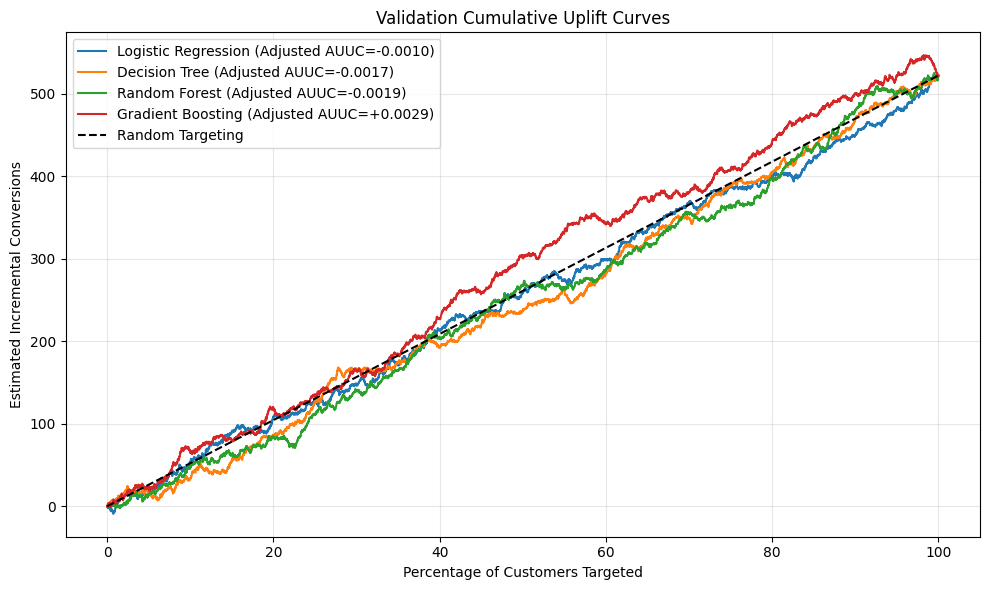

AUUC COMPARISON


,Model,Raw AUUC,Adjusted AUUC
3,Gradient Boosting,0.041143,0.002862
0,Logistic Regression,0.037281,-0.001000
1,Decision Tree,0.036533,-0.001748
2,Random Forest,0.036414,-0.001867


In [214]:
#mona asghar walid
# 4.8.2 Cumulative Uplift Curves and AUUC

def calculate_uplift_curve(uplift_scores):

    ranked = pd.DataFrame({
        "uplift": np.asarray(uplift_scores),
        "offer": t_valid.to_numpy(),
        "conversion": y_valid.to_numpy()
    }).sort_values(
        "uplift", ascending=False
    ).reset_index(drop=True)

    treated = (
        ranked["offer"] == "Discount"
    ).to_numpy()

    control = ~treated
    outcomes = ranked["conversion"].to_numpy()

    n_t = np.cumsum(treated)
    n_c = np.cumsum(control)

    buyers_t = np.cumsum(outcomes * treated)
    buyers_c = np.cumsum(outcomes * control)

    n = np.arange(1, len(ranked) + 1)

    # Cumulative estimated incremental conversions
    gain = np.zeros(len(ranked))

    valid = (n_t > 0) & (n_c > 0)

    gain[valid] = n[valid] * (
        buyers_t[valid] / n_t[valid]
        - buyers_c[valid] / n_c[valid]
    )

    x = np.concatenate(([0], n / len(ranked)))
    gain = np.concatenate(([0], gain))

    # Random-targeting reference
    random_line = gain[-1] * x

    # Normalized areas
    raw_auuc = np.trapezoid(gain, x) / len(ranked)

    adjusted_auuc = (
        np.trapezoid(gain - random_line, x)
        / len(ranked)
    )

    return x, gain, random_line, raw_auuc, adjusted_auuc


auuc_results = []

plt.figure(figsize=(10, 6))

for name, result in model_results.items():

    x, gain, random_line, raw, adjusted = (
        calculate_uplift_curve(result["uplift"])
    )

    auuc_results.append({
        "Model": name,
        "Raw AUUC": raw,
        "Adjusted AUUC": adjusted
    })

    plt.plot(
        x * 100,
        gain,
        label=f"{name} (Adjusted AUUC={adjusted:+.4f})"
    )

# Same random baseline for all models
plt.plot(
    x * 100,
    random_line,
    "--",
    color="black",
    label="Random Targeting"
)

plt.title("Validation Cumulative Uplift Curves")
plt.xlabel("Percentage of Customers Targeted")
plt.ylabel("Estimated Incremental Conversions")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

auuc_comparison = pd.DataFrame(
    auuc_results
).sort_values(
    "Adjusted AUUC",
    ascending=False
)

print("AUUC COMPARISON")

display(auuc_comparison.round(6))


 Validation Comparison Table


In [215]:
#Shaikah Ali Omran
# 4.8.3 Final Validation Comparison Table

top10_rows = []

for name, table in decile_tables.items():

    top10_rows.append({
        "Model": name,
        "Top-10% Lift": table.loc[
            table["Decile"] == 1,
            "Observed Lift"
        ].iloc[0]
    })

top10_df = pd.DataFrame(top10_rows)

final_comparison = (
    model_comparison
    .merge(top10_df, on="Model")
    .merge(auuc_comparison, on="Model")
    .sort_values("Adjusted AUUC", ascending=False)
    .reset_index(drop=True)
)

print("FINAL VALIDATION MODEL COMPARISON")

display(
    final_comparison.style.format({
        "Discount ROC-AUC": "{:.4f}",
        "Control ROC-AUC": "{:.4f}",
        "Average Predicted Uplift": "{:+.2%}",
        "Top-10% Lift": "{:+.2%}",
        "Raw AUUC": "{:.6f}",
        "Adjusted AUUC": "{:+.6f}"
    })
)


FINAL VALIDATION MODEL COMPARISON


,Model,Discount ROC-AUC,Control ROC-AUC,Average Predicted Uplift,Top-10% Lift,Raw AUUC,Adjusted AUUC
0,Gradient Boosting,0.5930,0.6544,+7.61%,+9.48%,0.041143,+0.002862
1,Logistic Regression,0.6042,0.6567,+7.59%,+7.75%,0.037281,-0.001000
2,Decision Tree,0.5805,0.6135,+7.53%,+4.92%,0.036533,-0.001748
3,Random Forest,0.5685,0.6356,+7.49%,+6.92%,0.036414,-0.001867


Overfitting EVALUATION


In [216]:
#mona asghar walid
# 5.9 Training vs Validation ROC-AUC

overfitting_rows = []

for name, result in model_results.items():

    for offer, key, valid_auc in [
        ("Discount", "discount_model",
         result["auc_discount"]),
        ("No Offer", "control_model",
         result["auc_control"])
    ]:

        model = result[key]

        group_mask = t_fit == offer

        X_group = X_fit.loc[group_mask]
        y_group = y_fit.loc[group_mask]

        train_probs = model.predict_proba(
            X_group
        )[:, 1]

        train_auc = roc_auc_score(
            y_group,
            train_probs
        )

        overfitting_rows.append({
            "Model": name,
            "Group": offer,
            "Training ROC-AUC": train_auc,
            "Validation ROC-AUC": valid_auc,
            "AUC Gap": train_auc - valid_auc
        })

overfitting_df = pd.DataFrame(overfitting_rows)

print("OVERFITTING EVALUATION")

display(
    overfitting_df.style.format({
        "Training ROC-AUC": "{:.4f}",
        "Validation ROC-AUC": "{:.4f}",
        "AUC Gap": "{:+.4f}"
    })
)


OVERFITTING EVALUATION


,Model,Group,Training ROC-AUC,Validation ROC-AUC,AUC Gap
0,Logistic Regression,Discount,0.6286,0.6042,+0.0244
1,Logistic Regression,No Offer,0.6586,0.6567,+0.0019
2,Decision Tree,Discount,0.6391,0.5805,+0.0586
3,Decision Tree,No Offer,0.6717,0.6135,+0.0581
4,Random Forest,Discount,0.7396,0.5685,+0.1711
5,Random Forest,No Offer,0.7885,0.6356,+0.1528
6,Gradient Boosting,Discount,0.6740,0.5930,+0.0809
7,Gradient Boosting,No Offer,0.7039,0.6544,+0.0495


In [217]:
#Shaikah Ali Omran
# 4.10 Provisional Model Selection

best_row = final_comparison.iloc[0]

best_model_name = best_row["Model"]

print("PROVISIONAL PREFERRED MODEL")
print("---------------------------")
print("Model:", best_model_name)

print(
    "Adjusted AUUC:",
    round(best_row["Adjusted AUUC"], 6)
)

print(
    "Top-10% Observed Lift:",
    f'{best_row["Top-10% Lift"]:+.2%}'
)

print(
    "Discount ROC-AUC:",
    round(best_row["Discount ROC-AUC"], 4)
)

print(
    "Control ROC-AUC:",
    round(best_row["Control ROC-AUC"], 4)
)

print("\nSelection based on validation results.")



PROVISIONAL PREFERRED MODEL
---------------------------
Model: Gradient Boosting
Adjusted AUUC: 0.002862
Top-10% Observed Lift: +9.48%
Discount ROC-AUC: 0.593
Control ROC-AUC: 0.6544

Selection based on validation results.


06 Hyperparameter Tuning and Evaluation

Hyperparameter tuning

In [218]:

#mona asghar walid
# STAGE 6.1 - GRADIENT BOOSTING HYPERPARAMETER TUNING


import numpy as np
import pandas as pd
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score

# Confirm required variables exist
required_vars = [
    "X_fit", "y_fit", "t_fit",
    "X_valid", "y_valid", "t_valid"
]

for var in required_vars:
    assert var in globals(), f"Missing variable: {var}"

# Model input features
cat_cols = ["zip_code", "channel"]
num_cols = [
    col for col in X_fit.columns
    if col not in cat_cols
]

assert len(X_fit.columns) == 9
assert "used_any_promo" not in X_fit.columns

def create_gb_pipeline():

    preprocessor = ColumnTransformer([
        ("numerical", StandardScaler(), num_cols),
        ("categorical",
         OneHotEncoder(handle_unknown="ignore"),
         cat_cols)
    ])

    return Pipeline([
        ("preprocessing", preprocessor),
        ("model", GradientBoostingClassifier(
            random_state=42
        ))
    ])

# Parameters must use model__ prefix inside Pipeline
param_grid = {
    "model__n_estimators": [100, 150],
    "model__learning_rate": [0.03, 0.05],
    "model__max_depth": [2, 3],
    "model__min_samples_leaf": [50, 100],
    "model__subsample": [0.8]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

tuned_models = {}

for offer in ["Discount", "No Offer"]:

    print(f"\nTuning Gradient Boosting: {offer}")

    mask = t_fit == offer

    grid = GridSearchCV(
        estimator=create_gb_pipeline(),
        param_grid=param_grid,
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid.fit(
        X_fit.loc[mask],
        y_fit.loc[mask]
    )

    tuned_models[offer] = grid.best_estimator_

    print("Best parameters:", grid.best_params_)
    print("Best CV ROC-AUC:",
          round(grid.best_score_, 4))

print("\nHyperparameter tuning completed.")



Tuning Gradient Boosting: Discount
Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_leaf': 100, 'model__n_estimators': 150, 'model__subsample': 0.8}
Best CV ROC-AUC: 0.6247

Tuning Gradient Boosting: No Offer
Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_leaf': 50, 'model__n_estimators': 150, 'model__subsample': 0.8}
Best CV ROC-AUC: 0.6479

Hyperparameter tuning completed.


In [219]:
#mona asghar walid
# STAGE 6.2 - VALIDATION COMPARISON


# Original Gradient Boosting from Stage 5
original_gb = model_results["Gradient Boosting"]

model_pairs = {
    "Original Gradient Boosting": {
        "Discount": original_gb["discount_model"],
        "No Offer": original_gb["control_model"]
    },
    "Tuned Gradient Boosting": tuned_models
}

def evaluate_uplift_pair(models):

    p_discount = models["Discount"].predict_proba(
        X_valid
    )[:, 1]

    p_control = models["No Offer"].predict_proba(
        X_valid
    )[:, 1]

    uplift = p_discount - p_control

    discount_mask = (t_valid == "Discount").to_numpy()
    control_mask = (t_valid == "No Offer").to_numpy()

    auc_discount = roc_auc_score(
        y_valid.loc[t_valid == "Discount"],
        p_discount[discount_mask]
    )

    auc_control = roc_auc_score(
        y_valid.loc[t_valid == "No Offer"],
        p_control[control_mask]
    )

    return {
        "Discount ROC-AUC": auc_discount,
        "Control ROC-AUC": auc_control,
        "uplift": uplift
    }

validation_predictions = {
    name: evaluate_uplift_pair(models)
    for name, models in model_pairs.items()
}

print("Validation probability predictions completed.")


Validation probability predictions completed.


In [220]:

#mona asghar walid
# STAGE 6.3 - UPLIFT METRICS


def calculate_uplift_metrics(scores):

    evaluation = pd.DataFrame({
        "offer": t_valid.to_numpy(),
        "conversion": y_valid.to_numpy(),
        "uplift": scores
    }).sort_values(
        "uplift", ascending=False
    ).reset_index(drop=True)

    n = len(evaluation)
    top_n = max(1, int(np.ceil(n * 0.10)))
    top = evaluation.iloc[:top_n]

    discount_top = top[top["offer"] == "Discount"]
    control_top = top[top["offer"] == "No Offer"]

    top10_lift = (
        discount_top["conversion"].mean()
        - control_top["conversion"].mean()
    )

    # Cumulative treatment and control counts
    is_treat = (
        evaluation["offer"] == "Discount"
    ).to_numpy()

    is_control = ~is_treat
    outcomes = evaluation["conversion"].to_numpy()

    cum_treat_n = np.cumsum(is_treat)
    cum_ctrl_n = np.cumsum(is_control)

    cum_treat_buyers = np.cumsum(
        outcomes * is_treat
    )

    cum_ctrl_buyers = np.cumsum(
        outcomes * is_control
    )

    # Estimate incremental conversions in targeted population
    treat_rate = np.divide(
        cum_treat_buyers,
        cum_treat_n,
        out=np.zeros(n, dtype=float),
        where=cum_treat_n > 0
    )

    ctrl_rate = np.divide(
        cum_ctrl_buyers,
        cum_ctrl_n,
        out=np.zeros(n, dtype=float),
        where=cum_ctrl_n > 0
    )

    cumulative_gain = (
        treat_rate - ctrl_rate
    ) * np.arange(1, n + 1)

    # Use only prefixes containing both groups
    valid_prefix = (
        (cum_treat_n > 0) & (cum_ctrl_n > 0)
    )

    cumulative_gain[~valid_prefix] = 0.0

    # Normalize by total validation population
    x = np.arange(1, n + 1) / n
    normalized_gain = cumulative_gain / n

    # Random targeting baseline
    random_gain = x * normalized_gain[-1]

    adjusted_auuc = np.trapezoid(
        normalized_gain - random_gain,
        x
    )

    return top10_lift, adjusted_auuc

comparison_rows = []

for name, result in validation_predictions.items():

    top_lift, auuc = calculate_uplift_metrics(
        result["uplift"]
    )

    comparison_rows.append({
        "Model": name,
        "Discount ROC-AUC": result["Discount ROC-AUC"],
        "Control ROC-AUC": result["Control ROC-AUC"],
        "Top-10% Lift": top_lift,
        "Adjusted AUUC": auuc
    })

tuning_comparison = pd.DataFrame(comparison_rows)

display(
    tuning_comparison.style.format({
        "Discount ROC-AUC": "{:.4f}",
        "Control ROC-AUC": "{:.4f}",
        "Top-10% Lift": "{:+.2%}",
        "Adjusted AUUC": "{:+.6f}"
    })
)


,Model,Discount ROC-AUC,Control ROC-AUC,Top-10% Lift,Adjusted AUUC
0,Original Gradient Boosting,0.5930,0.6544,+9.48%,+0.002862
1,Tuned Gradient Boosting,0.5898,0.6509,+9.86%,-0.002231


In [221]:

#mona asghar walid
# STAGE 6.4 - MODEL SELECTION


best_row = tuning_comparison.sort_values(
    "Adjusted AUUC",
    ascending=False
).iloc[0]

selected_version = best_row["Model"]

selected_models = model_pairs[selected_version]

print("SELECTED MODEL VERSION")
print("----------------------")
print(selected_version)
print("Adjusted AUUC:",
      round(best_row["Adjusted AUUC"], 6))
print("Top-10% Lift:",
      f'{best_row["Top-10% Lift"]:+.2%}')

print("\nSelection based on validation performance.")


SELECTED MODEL VERSION
----------------------
Original Gradient Boosting
Adjusted AUUC: 0.002862
Top-10% Lift: +9.48%

Selection based on validation performance.


Save the selected end-to-end pipeline

In [224]:

# STAGE 7.1 - SAVE SELECTED T-LEARNER FOR STREAMLIT

import pandas as pd
import joblib
import sklearn

from pathlib import Path
from sklearn.base import clone

# 1. Confirm selected model
print("Selected model:", selected_version)

# 2. Combine fitting and validation data

X_development = pd.concat([
    X_fit,
    X_valid
])

y_development = pd.concat([
    y_fit,
    y_valid
])

t_development = pd.concat([
    t_fit,
    t_valid
])

print("Development records:", len(X_development))

# 3. Refit the selected T-Learner
deployment_models = {}

for offer in ["Discount", "No Offer"]:

    mask = t_development == offer

    # Clone the selected complete pipeline
    model = clone(selected_models[offer])

    model.fit(
        X_development.loc[mask],
        y_development.loc[mask]
    )

    deployment_models[offer] = model

    print(
        offer,
        "training records:",
        int(mask.sum())
    )

# 4. Save the model and feature information
feature_columns = list(X_development.columns)

deployment_bundle = {
    "model_name": "Gradient Boosting",
    "model_version": selected_version,
    "discount_model": deployment_models["Discount"],
    "control_model": deployment_models["No Offer"],
    "feature_columns": feature_columns,
    "model_status": "provisional",
    "sklearn_version": sklearn.__version__
}

# 5. Create models folder
models_dir = Path("models")
models_dir.mkdir(parents=True, exist_ok=True)

# 6. Save the complete T-Learner
model_path = models_dir / "uplift_t_learner.joblib"

joblib.dump(
    deployment_bundle,
    model_path
)

print("\nFINAL DEPLOYMENT MODEL")
print("----------------------")
print("Selected version:", selected_version)
print("Saved to:", model_path)
print("Input features:", len(feature_columns))
print("Model saved successfully.")


Selected model: Original Gradient Boosting
Development records: 34090
Discount training records: 17045
No Offer training records: 17045

FINAL DEPLOYMENT MODEL
----------------------
Selected version: Original Gradient Boosting
Saved to: models/uplift_t_learner.joblib
Input features: 9
Model saved successfully.


In [225]:

# STAGE 7.2 - VERIFY DEPLOYMENT MODEL

loaded = joblib.load(model_path)

sample = X_valid.head(5)[
    loaded["feature_columns"]
].copy()

p_discount = loaded[
    "discount_model"
].predict_proba(sample)[:, 1]

p_control = loaded[
    "control_model"
].predict_proba(sample)[:, 1]

uplift = p_discount - p_control

verification = pd.DataFrame({
    "Discount Probability": p_discount,
    "No Offer Probability": p_control,
    "Predicted Uplift": uplift
})

display(
    verification.style.format({
        "Discount Probability": "{:.2%}",
        "No Offer Probability": "{:.2%}",
        "Predicted Uplift": "{:+.2%}"
    })
)

assert np.all(np.isfinite(uplift))

np.testing.assert_allclose(
    p_discount,
    deployment_models["Discount"].predict_proba(sample)[:, 1]
)

np.testing.assert_allclose(
    p_control,
    deployment_models["No Offer"].predict_proba(sample)[:, 1]
)

print("Saved model verification successful.")


,Discount Probability,No Offer Probability,Predicted Uplift
0,8.40%,2.45%,+5.95%
1,17.78%,9.86%,+7.92%
2,12.76%,5.05%,+7.71%
3,29.00%,39.17%,-10.17%
4,27.12%,12.00%,+15.12%


Saved model verification successful.
